# 04 · Kagome Heisenberg antiferromagnet: the archetypal spin-liquid candidate

$$H = J_1\sum_{\langle ij\rangle}\mathbf S_i\cdot\mathbf S_j\;(+J_2, J_3, J_\chi)$$

**What you will learn**
1. ED on 12- and 18-site clusters: no order, a small spin gap and many singlets below the first triplet.
2. The static structure factor $S(\mathbf q)$ has no Bragg peaks.
3. Partons: impose flux patterns, Gutzwiller-project them, and find that the U(1) Dirac spin liquid ($E\approx-0.4287$) beats the other ansätze.
4. A chiral spin liquid appears when a scalar-chirality term is added.
5. DMRG on a kagome cylinder.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import qslab
from qslab import lattice, models, ED
from qslab.parton import SpinonAnsatz, projected_state, GutzwillerVMC
from qslab.dmrg import DMRG

## 1. Exact diagonalisation

In [2]:
res = {}
for L in [(2, 2), (2, 3)]:
    lat = lattice.kagome(*L)
    H = models.kagome_heisenberg(lat)
    t = time.time()
    ed = ED(H, lat.N); w, v = ed.diagonalize(k=8)
    ed1 = ED(H, lat.N, n_up=lat.N // 2 + 1); w1, _ = ed1.diagonalize(k=2)
    res[lat.N] = (w, w1, ed, v)
    print(f"N={lat.N}: E0/N={w[0]/lat.N:.6f}  spin gap Δ_T={w1[0]-w[0]:.4f}  "
          f"singlets below triplet: {np.sum(w < w1[0]) - 1}   ({time.time()-t:.1f}s)")

N=12: E0/N=-0.453740  spin gap Δ_T=0.3827  singlets below triplet: 6   (0.7s)


N=18: E0/N=-0.447126  spin gap Δ_T=0.2846  singlets below triplet: 7   (2.2s)


Spectrum by total spin. Kagome clusters show **many low-lying singlets**, unlike the Anderson tower of states of an ordered magnet.

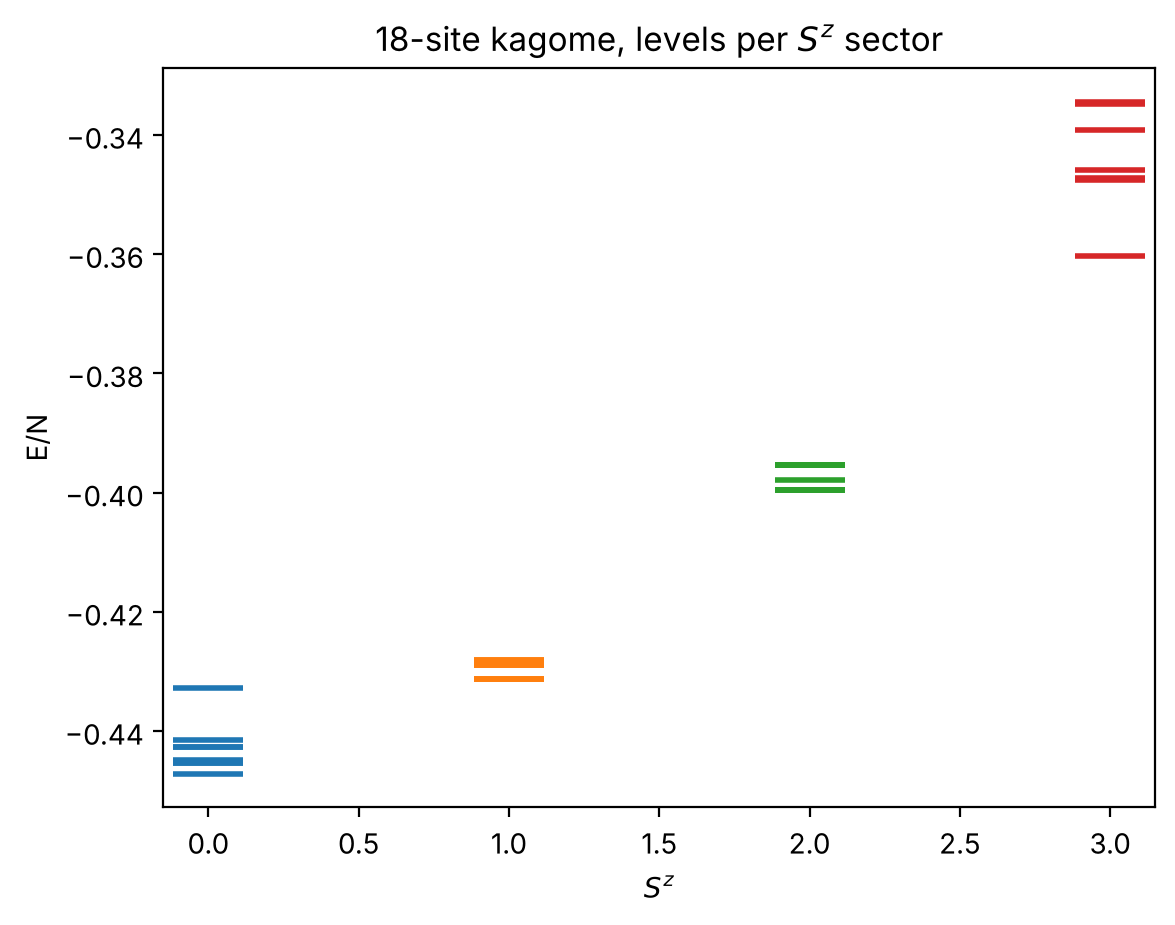

In [3]:
lat = lattice.kagome(2, 3); H = models.kagome_heisenberg(lat)
spec = qslab.spectrum_all_sectors(H, lat.N, k=8)
for twoSz, ws in spec.items():
    if twoSz <= 6:
        plt.plot([twoSz / 2] * len(ws), ws / lat.N, "_", ms=25, mew=2)
plt.xlabel("$S^z$"); plt.ylabel("E/N"); plt.title("18-site kagome, levels per $S^z$ sector"); plt.show()

## 2. Structure factor: no Bragg peaks

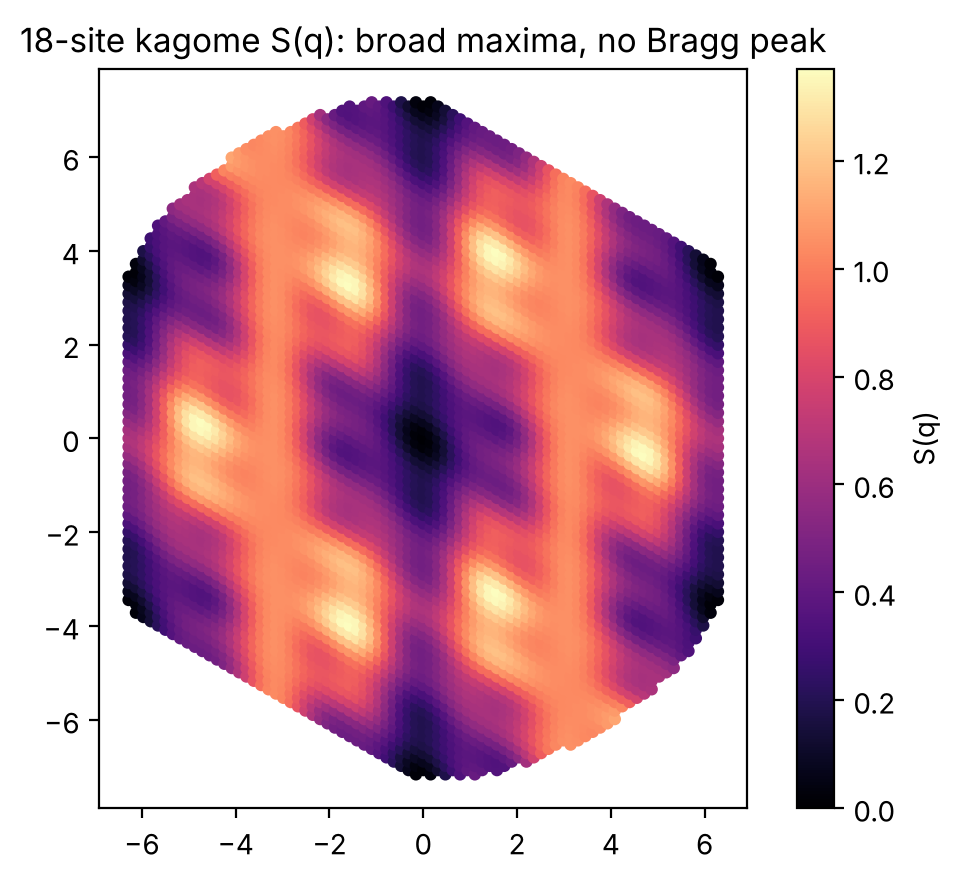

nearest-neighbour <S.S> = -0.27087183789654334


In [4]:
w, w1, ed, v = res[18]
lat = lattice.kagome(2, 3); psi = v[:, 0]
C = ed.spin_correlations(psi)
B = lat.reciprocal()
g = np.linspace(-2, 2, 81)
Q = np.array([a * B[0] + b * B[1] for a in g for b in g])
Q = Q[np.linalg.norm(Q, axis=1) < 2 * np.linalg.norm(B[0])]
Sq = ed.structure_factor(psi, lat.positions, Q, C=C)
plt.scatter(*Q.T, c=Sq, s=12, cmap="magma"); plt.colorbar(label="S(q)"); plt.gca().set_aspect("equal")
plt.title("18-site kagome S(q): broad maxima, no Bragg peak"); plt.show()
print("nearest-neighbour <S.S> =", C[lat.bonds(1)[0].i, lat.bonds(1)[0].j])

## 3. Parton ansätze and Gutzwiller projection
`hoppings_from_flux` finds a gauge for *any* flux pattern on *any* cluster: real 0/π fluxes by GF(2) elimination and general fluxes by least squares.

In [5]:
ansatze = {"U(1) Dirac [0,π]": {"up": 0, "down": 0, "hexagon": np.pi},
           "[π,0]": {"up": np.pi, "down": np.pi, "hexagon": 0},
           "uniform [0,0]": {"up": 0, "down": 0, "hexagon": 0},
           "chiral [π/2,0]": {"up": np.pi / 2, "down": np.pi / 2, "hexagon": 0}}
lat12 = lattice.kagome(2, 2); ed12 = ED(models.kagome_heisenberg(lat12), 12)
w12, v12 = ed12.diagonalize(k=6); E12, g12 = w12[0], v12[:, 0]
for name, fl in ansatze.items():
    for tw in [(0, 0), (np.pi, 0), (0, np.pi), (np.pi, np.pi)]:
        try:
            ans = SpinonAnsatz.from_flux(lat12, fl, twist=tw)
        except ValueError:
            continue
        if ans.fermi_gap() > 1e-6:
            break
    basis, psi = projected_state(ans)
    ov = np.abs(v12.conj().T @ psi)
    print(f"{name:18s} twist={tw}: E/N = {np.vdot(psi, ed12.matvec(psi)).real/12:.5f}   "
          f"|<GS|psi>| = {ov[0]:.3f}   largest overlap {ov.max():.3f} with level {ov.argmax()}")
print("exact E/N =", E12 / 12)

U(1) Dirac [0,π]   twist=(0, 0): E/N = -0.43066   |<GS|psi>| = 0.000   largest overlap 0.727 with level 1
[π,0]              twist=(0, 0): E/N = -0.42098   |<GS|psi>| = 0.000   largest overlap 0.858 with level 3
uniform [0,0]      twist=(3.141592653589793, 0): E/N = -0.42098   |<GS|psi>| = 0.000   largest overlap 0.858 with level 3
chiral [π/2,0]     twist=(0, 0): E/N = -0.39461   |<GS|psi>| = 0.000   largest overlap 0.748 with level 1
exact E/N = -0.45373960141432135


On this tiny cluster the projected DSL is **orthogonal** to the exact ground state, because the two carry different lattice quantum numbers.
It has a large overlap with the first excited singlet instead. Matching quantum numbers is an essential check in parton studies. The energy comparison only becomes meaningful on larger clusters, where VMC gives about $-0.429$ against roughly $-0.438$ from DMRG.

Spinon density of states: the Dirac spin liquid has $\rho(\omega)\propto|\omega|$ at the Fermi level.

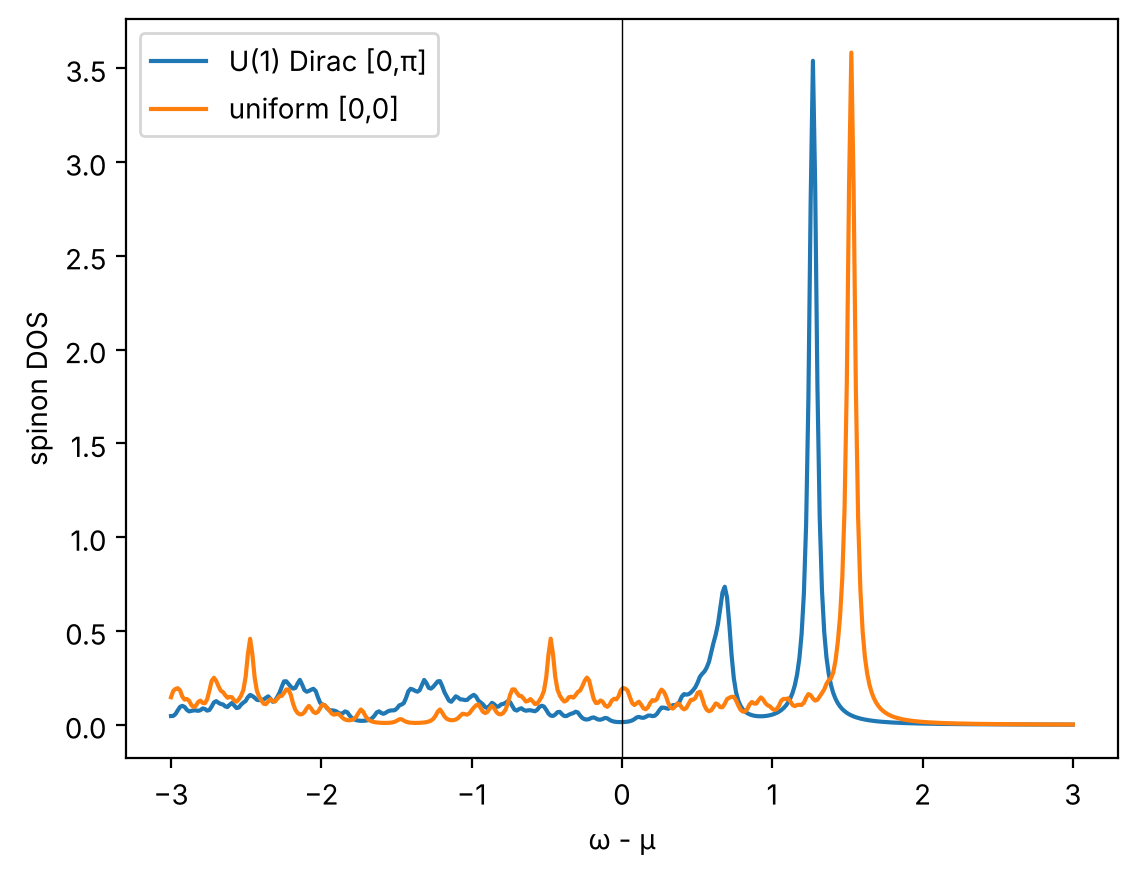

In [6]:
big = lattice.kagome(24, 24)
om = np.linspace(-3, 3, 400)
for name in ["U(1) Dirac [0,π]", "uniform [0,0]"]:
    ans = SpinonAnsatz.from_flux(big, ansatze[name])
    mu = 0.5 * (ans.eps[ans.n_occ - 1] + ans.eps[ans.n_occ])
    plt.plot(om, ans.dos(om + mu, eta=0.03), label=name)
plt.axvline(0, c="k", lw=0.5); plt.xlabel("ω - μ"); plt.ylabel("spinon DOS"); plt.legend(); plt.show()

**VMC on large clusters.** Markov chains run in parallel (threads here, or MPI ranks under `mpirun`). The literature value for the projected DSL is $-0.42866\,J$.

In [7]:
for L in [4, 6]:
    lat = lattice.kagome(L, L)
    ans = SpinonAnsatz.from_flux(lat, ansatze["U(1) Dirac [0,π]"])
    t = time.time(); r = GutzwillerVMC(ans).run(n_sweeps=300, n_therm=50, n_chains=2)
    print(f"N={lat.N:4d}: E/N = {r['E_per_site']:.4f} ± {r['err_per_site']:.4f}   ({time.time()-t:.0f}s)")

N=  48: E/N = -0.4296 ± 0.0004   (1s)


N= 108: E/N = -0.4291 ± 0.0009   (3s)


## 4. Chiral spin liquid from a scalar-chirality term
$J_\chi\sum_\triangle \mathbf S_i\cdot(\mathbf S_j\times\mathbf S_k)$ breaks time reversal. The ground state develops a chirality and, in the thermodynamic limit, becomes a Kalmeyer-Laughlin state.

In [8]:
lat = lattice.kagome(2, 2)
tri = lat.plaquettes("up")[0].sites
chi_op = qslab.scalar_chirality(*tri)
for Jchi in [0, 0.1, 0.2, 0.4]:
    ed = ED(models.kagome_heisenberg(lat, Jchi=Jchi), 12)
    E, psi = ed.ground_state()
    print(f"Jchi={Jchi:.1f}: E/N={E/12:.5f}  <S.(SxS)>_up = {np.real(ed.expect(chi_op, psi)):+.4f}")

Jchi=0.0: E/N=-0.45374  <S.(SxS)>_up = +0.0000


Jchi=0.1: E/N=-0.45457  <S.(SxS)>_up = -0.0249


Jchi=0.2: E/N=-0.46020  <S.(SxS)>_up = -0.1559


Jchi=0.4: E/N=-0.48279  <S.(SxS)>_up = -0.1818


## 5. DMRG on a kagome cylinder
Kagome cylinders with circumference 2 cells (6 sites per column) and length 4 cells.

sweep  0  chi=  16  E=-10.3494215189  E/N=-0.43122590  trunc=0.0e+00  S_mid=0.8169


sweep  1  chi=  32  E=-10.6243089012  E/N=-0.44267954  trunc=6.2e-05  S_mid=1.3496


sweep  2  chi=  64  E=-10.6275908353  E/N=-0.44281628  trunc=4.1e-06  S_mid=1.4034


sweep  3  chi= 128  E=-10.6276837517  E/N=-0.44282016  trunc=1.9e-07  S_mid=1.4206


sweep  4  chi= 160  E=-10.6276850232  E/N=-0.44282021  trunc=3.5e-08  S_mid=1.4207


sweep  5  chi= 160  E=-10.6276850233  E/N=-0.44282021  trunc=3.5e-08  S_mid=1.4207


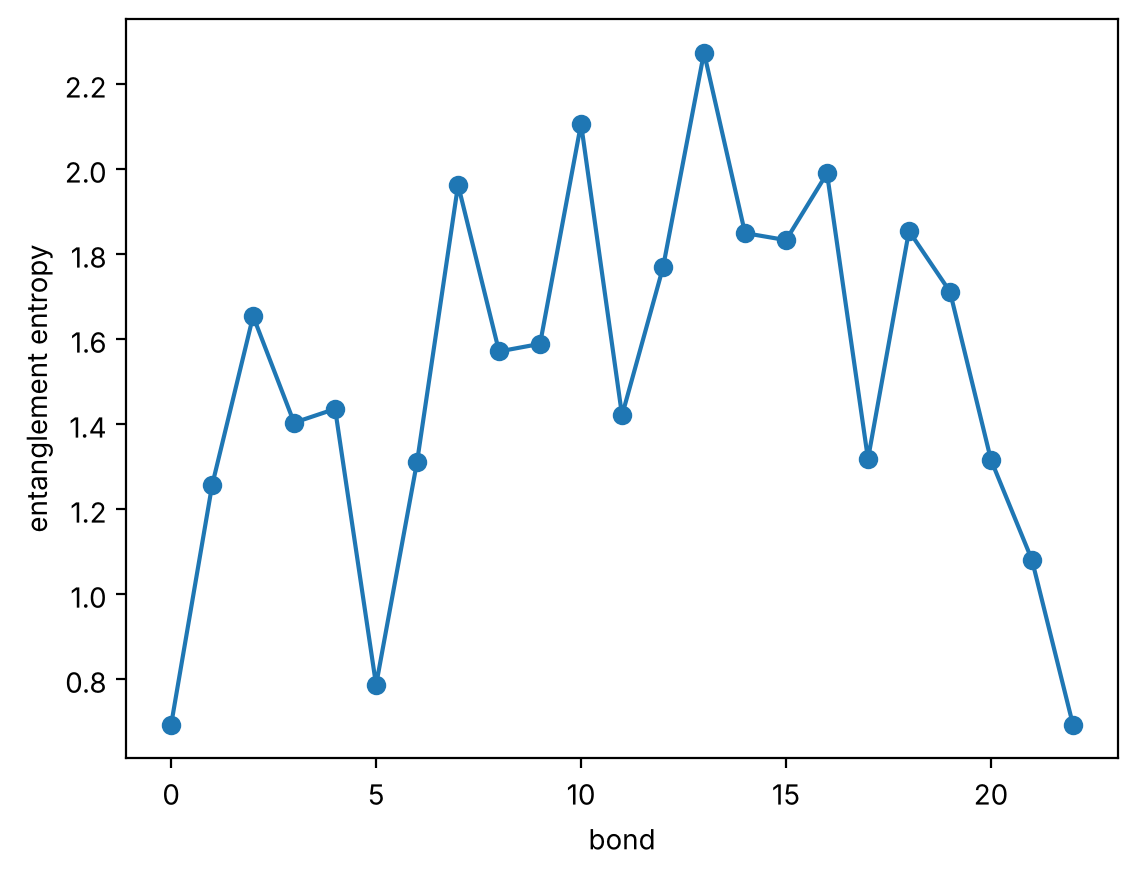

In [9]:
lat = lattice.kagome(4, 2, bc="cylinder")
H = models.kagome_heisenberg(lat)
d = DMRG(H, lat.N, chi_max=160)
d.run(n_sweeps=8, verbose=True)
plt.plot(d.entropies, "o-"); plt.xlabel("bond"); plt.ylabel("entanglement entropy"); plt.show()

## Quiz

In [10]:
from qslab import quiz
quiz.show("kagome")

=== Kagome Heisenberg antiferromagnet ===
Corner-sharing triangles, 3 sites per unit cell.

Q1. [numeric] Exact ground-state energy per site of the 12-site (2x2 cell) kagome torus?
    -> numeric answer (tolerance 2e-05)

Q2. [mcq] Which spinon flux pattern defines the U(1) Dirac spin liquid (Ran-Hermele-Lee-Wen)?
    (a) pi through triangles, 0 through hexagons
    (b) 0 through triangles, pi through hexagons
    (c) pi/2 through triangles
    (d) 0 everywhere

Q3. [numeric] VMC energy per site of the projected U(1) Dirac spin liquid (large torus)?
    -> numeric answer (tolerance 0.002)

Q4. [mcq] What is the classical ground-state degeneracy of the kagome AFM?
    (a) Neel
    (b) extensive (any configuration with total spin 0 on every triangle)
    (c) unique 120-degree state
    (d) two-fold

Q5. [mcq] Which of these stabilises a chiral spin liquid on kagome?
    (a) a staggered field
    (b) J2 = J3 ~ 0.5 or a scalar chirality term Jchi
    (c) an Ising anisotropy
    (d) a ferro